# AAUT1IA

## Import libraries

In [19]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import os
from pathlib import Path
from dotenv import load_dotenv

## Load data

In [20]:
data = pd.read_csv(Path("datasets/AAPL.csv"))

## Load environment variables

In [21]:
load_dotenv()
api_key = os.getenv('ALPHA_VANTAGE_API_KEY')

## Analyze data

In [22]:
data.dtypes

Date             object
Open            float64
High            float64
Low             float64
Close           float64
Volume            int64
Dividends       float64
Stock Splits    float64
dtype: object

In [23]:
data.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,11082.000000,11082.000000,11082.000000,11082.000000,1.108200e+04,11082.000000,11082.000000
mean,22.999465,23.245089,22.765351,23.016211,3.160454e+08,0.000792,0.001534
std,48.624006,49.135626,48.147580,48.668007,3.350015e+08,0.012178,0.083346
min,0.038245,0.038245,0.037815,0.037815,0.000000e+00,0.000000,0.000000
25%,0.242789,0.248055,0.237743,0.242844,1.116802e+08,0.000000,0.000000
50%,0.441069,0.449738,0.433847,0.441014,2.040030e+08,0.000000,0.000000
75%,18.006522,18.116080,17.709846,17.926857,3.970008e+08,0.000000,0.000000
max,235.947003,237.229001,234.192340,236.220108,7.421641e+09,0.250000,7.000000


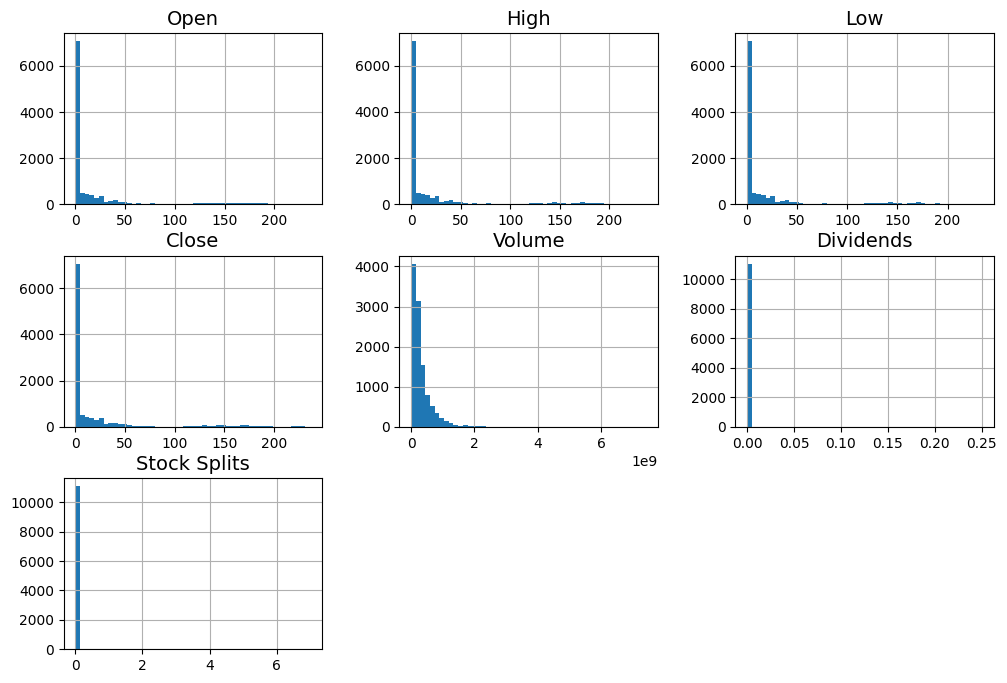

In [24]:
import matplotlib.pyplot as plt

# extra code – the next 5 lines define the default font sizes
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

data.hist(bins=50, figsize=(12, 8))
plt.show()

In [25]:
data['Date'] = pd.to_datetime(data['Date'], utc=True)

data['Quarter'] = data['Date'].dt.quarter


## Calculating Features 

### Calculation features on data

In [26]:
data['week_number'] = data['Date'].dt.isocalendar().week
data['week_day'] = data['Date'].dt.weekday
data['month']  = data['Date'].dt.month


### Calculating features on price 

In [27]:
#### Price Based Features #####

# Daily Range
data["Daily Range"] = data["High"] - data["Low"]

# Candle Size
data["Candle Size"] = (data["Close"] - data["Open"]).abs()

# 3. Direction
data["Direction"] = (data["Close"] > data["Open"]).astype(int)

# 4. Percentage Change
data["Percentage Change"] = ((data["Close"] - data["Open"]) / data["Open"]) * 100

# 5. Log Returns
data["Log Return"] = np.log(data["Close"] / data["Close"].shift(1))

# 6. Momentum (10-day)
data["Momentum_10"] = data["Close"] - data["Close"].shift(10)


# ===================== TREND AND MOVING AVERAGES =====================

# Simple Moving Average (SMA)
data["SMA_5"] = data["Close"].rolling(window=5).mean()
data["SMA_20"] = data["Close"].rolling(window=20).mean()

# Exponential Moving Average (EMA)
data["EMA_5"] = data["Close"].ewm(span=5, adjust=False).mean()
data["EMA_20"] = data["Close"].ewm(span=20, adjust=False).mean()


# ===================== VOLATILITY FEATURES =====================

# Rolling Standard Deviation (Volatility)
data["5-Day Volatility"] = data["Close"].rolling(window=5).std()


# Average True Range (ATR)
#data['TR'] = data[['High', 'Low', 'Close']].apply(
#    lambda row: max(row['High'] - row['Low'], 
#                    abs(row['High'] - row['Close'].shift(1)), 
#                    abs(row['Low'] - row['Close'].shift(1))) if not pd.isnull(row['Close'].shift(1)) else row['High'] - row['Low'], axis=1)
#data["ATR"] = data["TR"].rolling(window=14).mean()


# Bollinger Bands
data['Bollinger_SMA_20'] = data['Close'].rolling(window=20).mean()
data['Bollinger_Upper Band'] = data['Bollinger_SMA_20'] + (2 * data['Close'].rolling(window=20).std())
data['Bollinger_Lower Band'] = data['Bollinger_SMA_20'] - (2 * data['Close'].rolling(window=20).std())



# ===================== MOMENTUM AND OSCILLATORS =====================

# Relative Strength Index (RSI)
data['Change'] = data['Close'] - data['Close'].shift(1)
data['Gain'] = data['Change'].where(data['Change'] > 0, 0)
data['Loss'] = -data['Change'].where(data['Change'] < 0, 0)
data['Avg_Gain'] = data['Gain'].rolling(window=14).mean()
data['Avg_Loss'] = data['Loss'].rolling(window=14).mean()
data['RS'] = data['Avg_Gain'] / data['Avg_Loss']
data['RSI'] = 100 - (100 / (1 + data['RS']))



# Rate of Change (ROC)
data['ROC_10'] = ((data['Close'] - data['Close'].shift(10)) / data['Close'].shift(10)) * 100

# ===================== VOLUME-BASED FEATURES =====================

# Volume Moving Average
data['Volume_SMA_10'] = data['Volume'].rolling(window=10).mean()

# Volume Change (Percentage)
data['Volume Change'] = data['Volume'].pct_change() * 100

# On-Balance Volume (OBV)
data['OBV'] = (data['Volume'] * ((data['Close'] > data['Close'].shift(1)).astype(int) - (data['Close'] < data['Close'].shift(1)).astype(int))).cumsum()

# ===================== RETURN-BASED FEATURES =====================

# Daily Return
data['Daily Return'] = data['Close'].pct_change()

# Cumulative Return
data['Cumulative Return'] = (1 + data['Daily Return']).cumprod() - 1

# ===================== STATISTICAL FEATURES =====================

# Z-Score Normalization
data['Z-Score'] = (data['Close'] - data['Close'].rolling(window=20).mean()) / data['Close'].rolling(window=20).std()

# Skewness
data['Rolling Skewness'] = data['Close'].rolling(window=20).skew()

# Kurtosis
data['Rolling Kurtosis'] = data['Close'].rolling(window=20).kurt()

In [28]:
# 2. Calculate returns over different periods
data['7-Day Return'] = (data['Close'] / data['Close'].shift(7) - 1) * 100  # 7 days
data['1-Month Return'] = (data['Close'] / data['Close'].shift(30) - 1) * 100  # 30 days
data['6-Month Return'] = (data['Close'] / data['Close'].shift(182) - 1) * 100  # ~6 months
data['1-Year Return'] = (data['Close'] / data['Close'].shift(365) - 1) * 100  # 1 year

# 3. Calculate total return (all-time return from the first date)
data['Total Return'] = (data['Close'] / data['Close'].iloc[0] - 1) * 100

In [29]:
row_1000 = data.iloc[1000]

print(row_1000)



Date                    1984-11-26 05:00:00+00:00
Open                                     0.082506
High                                     0.082506
Low                                      0.082506
Close                                    0.082506
Volume                                  100643200
Dividends                                     0.0
Stock Splits                                  0.0
Quarter                                         4
week_number                                    48
week_day                                        0
month                                          11
Daily Range                                   0.0
Candle Size                                   0.0
Direction                                       0
Percentage Change                             0.0
Log Return                               0.010471
Momentum_10                              0.002578
SMA_5                                    0.079326
SMA_20                                   0.083021


### Calculating feature for GDP data

In [36]:
url_real_gdp_data = 'https://www.alphavantage.co/query?function=REAL_GDP&interval=quarterly&apikey={api_key}'
request_real_gdp_data = requests.get(url_real_gdp_data)
real_gdp_data = request_real_gdp_data.json()

real_gdp_quarterly = real_gdp_data.get('data', [])

real_gdp_mapping = {
    entry['date'][:4] + '-Q' + str((int(entry['date'][5:7]) - 1) // 3 + 1): entry['value']
    for entry in real_gdp_quarterly
}

def get_quarterly_gdp_from_quarter(row):
    quarter_key = row['Date'].strftime('%Y') + '-Q' + str(row['Quarter'])
    return real_gdp_mapping.get(quarter_key, None)

data['REAL_GDP'] = data.apply(get_quarterly_gdp_from_quarter, axis=1)


### Calculating feature GDP per capita data

In [37]:
url_real_gdp_per_capita_data = 'https://www.alphavantage.co/query?function=REAL_GDP_PER_CAPITA&interval=quarterly&apikey={api_key}'
request_real_gdp_per_capita_data = requests.get(url_real_gdp_per_capita_data)
real_gdp_per_capita_data = request_real_gdp_per_capita_data.json()

real_gdp_per_capita_quarterly = real_gdp_per_capita_data.get('data', [])

real_gdp_per_capita_mapping = {
    entry['date'][:4] + '-Q' + str((int(entry['date'][5:7]) - 1) // 3 + 1): entry['value']
    for entry in real_gdp_per_capita_quarterly
}

def get_quarterly_gdp_per_capita_from_quarter(row):
    quarter_key = row['Date'].strftime('%Y') + '-Q' + str(row['Quarter'])
    return real_gdp_per_capita_mapping.get(quarter_key, None)

data['REAL_GDP_PER_CAPITA'] = data.apply(get_quarterly_gdp_per_capita_from_quarter, axis=1)
